# DANet-S Training for Malaria Cell Classification

This notebook documents the implementation and training of DANet-S for binary classification of segmented red blood cells as Parasitized or Uninfected. It uses the shared dataset manifest prepared during the data-preparation stage and preserves the completed 75-epoch training results for evaluation.


## 1. Objective and Reproduction Scope

The selected base paper is *DANet: A Lightweight Dilated Attention Network for Malaria Parasite Detection* (2025). The implementation preserves the official DANet-S feature extractor and uses two LogSoftMax outputs to match the binary label mapping.

The test split is created but remains unused in this notebook. Model selection uses validation loss only. Final test evaluation is reserved for the evaluation stage.


## 2. Environment and Shared Artifacts


In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: Not available")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/malaria_danet")
MANIFEST_PATH = PROJECT_DIR / "split_manifest.csv"
CONFIG_PATH = PROJECT_DIR / "data_config.json"
TRAINING_DIR = PROJECT_DIR / "danet_training"
FIGURES_DIR = TRAINING_DIR / "figures"

FINAL_MODEL_PATH = TRAINING_DIR / "danet_s_best_final.pth"
FINAL_CONFIG_PATH = TRAINING_DIR / "danet_training_config_final.json"
FINAL_HISTORY_PATH = TRAINING_DIR / "danet_training_history_final.csv"
SUMMARY_PATH = TRAINING_DIR / "danet_training_summary.md"
ARTIFACT_MANIFEST_PATH = TRAINING_DIR / "training_artifact_manifest.json"

print("Project folder:", PROJECT_DIR)
print("Manifest found:", MANIFEST_PATH.exists())
print("Data configuration found:", CONFIG_PATH.exists())
print("Final model found:", FINAL_MODEL_PATH.exists())


Project folder: /content/drive/MyDrive/malaria_danet
Manifest found: True
Data configuration found: True
Final model found: True


In [4]:
import json

with open(CONFIG_PATH, "r") as file:
    data_config = json.load(file)

print(json.dumps(data_config, indent=2))

{
  "dataset": "NIH/NLM Malaria Cell Images",
  "dataset_url": "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip",
  "base_paper": "DANet: A Lightweight Dilated Attention Network for Malaria Parasite Detection",
  "base_paper_doi": "10.1038/s41598-025-20402-1",
  "baseline_variant": "DANet-S with LogSoftMax",
  "total_images": 27558,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "split_protocol": "stratified image-level split",
  "split_seed": 42,
  "split_ratios": {
    "train": 0.7,
    "validation": 0.1,
    "test": 0.2
  },
  "split_counts": {
    "train": 19290,
    "validation": 2756,
    "test": 5512
  },
  "input_size": [
    224,
    224
  ],
  "pixel_scaling": "[0, 255] to [0, 1]",
  "training_augmentation": {
    "rotation_degrees": 15,
    "horizontal_flip_probability": 0.2,
    "vertical_flip_probability": 0.2
  },
  "batch_size": 64,
  "unreadable_images": 0,
  "exact_duplicate_groups": 0,
  "unique_official_patient_ids": 201,
  "pati

In [5]:
import pandas as pd

manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest shape:", manifest.shape)
print("Columns:", manifest.columns.tolist())
display(manifest.head())

Manifest shape: (27558, 9)
Columns: ['relative_path', 'filename', 'class_name', 'label', 'width', 'height', 'sha256', 'official_patient_id', 'split']


,relative_path,filename,class_name,label,width,height,sha256,official_patient_id,split
0,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_128.png,Uninfected,0,160,139,c8ca3d1d4a4b5fd3880b117d5157b580b4cec277d905ff...,C100P61ThinF,train
1,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_131.png,Uninfected,0,145,136,e3ae546255ee877dd6f2d3a05b70cb34d0484d79f28fef...,C100P61ThinF,test
2,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_144.png,Uninfected,0,145,142,b96da0f59af6104d38d6196f1e98560490c19fd67cf948...,C100P61ThinF,validation
3,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_21.png,Uninfected,0,100,112,9d6e182c041a37d43e997cad8b860e8ee5aedd5285e919...,C100P61ThinF,validation
4,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_25.png,Uninfected,0,124,139,ca451e7bc57abca9aa8bf280d89a1bb1ba8191c6981de7...,C100P61ThinF,test


In [6]:
split_counts = manifest["split"].value_counts()
class_counts = pd.crosstab(manifest["split"], manifest["class_name"])

print("Split counts:")
display(split_counts)

print("Class counts by split:")
display(class_counts)

Split counts:


,count
split,
train,19290
test,5512
validation,2756


Class counts by split:


class_name,Parasitized,Uninfected
split,,
test,2756,2756
train,9645,9645
validation,1378,1378


## 3. Dataset Reconstruction and Validation

The dataset is downloaded from the official NIH/NLM source. Every path in the saved manifest is verified before constructing datasets. The manifest retains the original 70/10/20 stratified image-level split.


In [7]:
dataset_url = "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip"
DATA_ROOT = Path("/content/malaria_data")
IMAGE_DIR = DATA_ROOT / "cell_images"
ZIP_PATH = DATA_ROOT / "cell_images.zip"

print("Dataset URL:", dataset_url)
print("Image folder:", IMAGE_DIR)


Dataset URL: https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip
Image folder: /content/malaria_data/cell_images


In [8]:
import urllib.request

DATA_ROOT.mkdir(parents=True, exist_ok=True)
ZIP_PATH = DATA_ROOT / "cell_images.zip"

dataset_url = "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip"

if not ZIP_PATH.exists():
    urllib.request.urlretrieve(dataset_url, ZIP_PATH)

print("Downloaded file:", ZIP_PATH)
print("File size:", round(ZIP_PATH.stat().st_size / (1024**2), 1), "MB")

Downloaded file: /content/malaria_data/cell_images.zip
File size: 337.1 MB


In [9]:
import zipfile

if not IMAGE_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:
        zip_file.extractall(DATA_ROOT)

print("Extraction complete.")
print("Dataset folders:", sorted(path.name for path in IMAGE_DIR.iterdir() if path.is_dir()))

Extraction complete.
Dataset folders: ['Parasitized', 'Uninfected']


In [10]:
image_paths = manifest["relative_path"].map(lambda path: IMAGE_DIR / path)
missing_paths = image_paths[~image_paths.map(Path.exists)]

print("Manifest images:", len(image_paths))
print("Missing images:", len(missing_paths))

if not missing_paths.empty:
    display(missing_paths.head())

Manifest images: 27558
Missing images: 0


## 4. Reproducibility, Transformations, and Data Loaders


In [11]:
import random
import numpy as np

SEED = data_config["split_seed"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Reproducibility seed:", SEED)

Reproducibility seed: 42


In [12]:
from torchvision import transforms

image_size = tuple(data_config["input_size"])
augmentation = data_config["training_augmentation"]

train_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.RandomRotation(augmentation["rotation_degrees"]),
    transforms.RandomHorizontalFlip(
        p=augmentation["horizontal_flip_probability"]
    ),
    transforms.RandomVerticalFlip(
        p=augmentation["vertical_flip_probability"]
    ),
    transforms.ToTensor(),
])

evaluation_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
])

print("Training transformations:")
print(train_transform)

print("\nEvaluation transformations:")
print(evaluation_transform)

Training transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    RandomHorizontalFlip(p=0.2)
    RandomVerticalFlip(p=0.2)
    ToTensor()
)

Evaluation transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


In [13]:
from PIL import Image
from torch.utils.data import Dataset

class MalariaManifestDataset(Dataset):
    def __init__(self, records, image_root, transform=None):
        self.records = records.reset_index(drop=True).copy()
        self.image_root = Path(image_root)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        row = self.records.iloc[index]
        image_path = self.image_root / row["relative_path"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = int(row["label"])
        return image, label

In [14]:
train_records = manifest[manifest["split"] == "train"]
validation_records = manifest[manifest["split"] == "validation"]
test_records = manifest[manifest["split"] == "test"]

train_dataset = MalariaManifestDataset(
    train_records,
    IMAGE_DIR,
    train_transform,
)

validation_dataset = MalariaManifestDataset(
    validation_records,
    IMAGE_DIR,
    evaluation_transform,
)

test_dataset = MalariaManifestDataset(
    test_records,
    IMAGE_DIR,
    evaluation_transform,
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))
print("Test samples:", len(test_dataset))

Training samples: 19290
Validation samples: 2756
Test samples: 5512


In [15]:
from torch.utils.data import DataLoader

batch_size = data_config["batch_size"]

resume_loader_generator = torch.Generator()
resume_loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    generator=resume_loader_generator,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))
print("Data-loader workers:", 0)

Training batches: 302
Validation batches: 44
Test batches: 87
Data-loader workers: 0


In [16]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Pixel range:", float(images.min()), "to", float(images.max()))
print("Class counts:", torch.bincount(labels, minlength=2))

Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
Image dtype: torch.float32
Pixel range: 0.0 to 0.9529411792755127
Class counts: tensor([37, 27])


## 5. DANet-S Architecture

Each dilated attention block extracts features at dilation rates 1, 2, and 3, combines average- and max-pooled representations, and applies channel attention before projecting to the next stage. The network contains 2,310,842 trainable parameters.

The official public implementation hardcodes more than two classifier outputs. This reproduction changes only the final classifier width to two outputs so it matches the saved binary class mapping.


In [17]:
import torch.nn as nn

class DilatedAttentionBlockS(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.input_projection = nn.Conv2d(
            in_channels,
            in_channels,
            kernel_size=1,
        )

        self.dilated_conv_1 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                in_channels,
                kernel_size=3,
                padding=1,
                dilation=1,
            ),
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(),
        )

        self.dilated_conv_2 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                in_channels,
                kernel_size=3,
                padding=2,
                dilation=2,
            ),
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(),
        )

        self.dilated_conv_3 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                in_channels,
                kernel_size=3,
                padding=3,
                dilation=3,
            ),
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(),
        )

        self.average_pool = nn.AvgPool2d(
            kernel_size=3,
            stride=1,
            padding=1,
        )

        self.maximum_pool = nn.MaxPool2d(
            kernel_size=3,
            stride=1,
            padding=1,
        )

        self.attention_features = nn.Sequential(
            nn.Conv2d(
                6 * in_channels,
                in_channels,
                kernel_size=3,
                padding=1,
            ),
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(),
        )

        self.attention_projection = nn.Conv2d(
            in_channels,
            in_channels,
            kernel_size=1,
        )

        self.channel_attention = nn.Softmax(dim=1)

        self.output_projection = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
            ),
            nn.InstanceNorm2d(out_channels, affine=True),
            nn.LeakyReLU(),
        )

    def forward(self, inputs):
        projected = self.input_projection(inputs)

        features_1 = self.dilated_conv_1(projected)
        features_2 = self.dilated_conv_2(features_1)
        features_3 = self.dilated_conv_3(features_2)

        multiscale_features = torch.cat(
            [features_1, features_2, features_3],
            dim=1,
        )

        pooled_features = torch.cat(
            [
                self.average_pool(multiscale_features),
                self.maximum_pool(multiscale_features),
            ],
            dim=1,
        )

        attention = self.attention_features(pooled_features)
        attention = self.attention_projection(attention)
        attention = self.channel_attention(attention)

        return self.output_projection(attention * inputs)

In [18]:
class DANetS(nn.Module):
    def __init__(self, num_classes=2, base_channels=8):
        super().__init__()

        channels = base_channels

        self.stem = nn.Sequential(
            nn.Conv2d(
                3,
                channels,
                kernel_size=3,
                padding=1,
            ),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.block_1 = DilatedAttentionBlockS(channels, channels)
        self.pool_1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.block_2 = DilatedAttentionBlockS(channels, 2 * channels)
        self.block_3 = DilatedAttentionBlockS(2 * channels, 2 * channels)
        self.pool_2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.block_4 = DilatedAttentionBlockS(2 * channels, 4 * channels)
        self.block_5 = DilatedAttentionBlockS(4 * channels, 4 * channels)
        self.pool_3 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.block_6 = DilatedAttentionBlockS(4 * channels, 8 * channels)
        self.block_7 = DilatedAttentionBlockS(8 * channels, 8 * channels)
        self.pool_4 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.block_8 = DilatedAttentionBlockS(8 * channels, 16 * channels)
        self.block_9 = DilatedAttentionBlockS(16 * channels, 16 * channels)

        self.global_pool = nn.AvgPool2d(kernel_size=7, stride=2)
        self.flatten = nn.Flatten()

        self.classifier = nn.Sequential(
            nn.Linear(16 * channels, 8 * channels),
            nn.ReLU(),
            nn.Linear(8 * channels, num_classes),
            nn.LogSoftmax(dim=1),
        )

    def forward(self, inputs):
        features = self.stem(inputs)

        features = self.block_1(features)
        features = self.pool_1(features)

        features = self.block_2(features)
        features = self.block_3(features)
        features = self.pool_2(features)

        features = self.block_4(features)
        features = self.block_5(features)
        features = self.pool_3(features)

        features = self.block_6(features)
        features = self.block_7(features)
        features = self.pool_4(features)

        features = self.block_8(features)
        features = self.block_9(features)

        features = self.global_pool(features)
        features = self.flatten(features)

        return self.classifier(features)

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = DANetS(
    num_classes=len(data_config["class_mapping"]),
).to(device)

total_parameters = sum(parameter.numel() for parameter in model.parameters())
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Device:", device)
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")

Device: cuda
Total parameters: 2,310,842
Trainable parameters: 2,310,842


In [20]:
model.eval()

with torch.no_grad():
    sample_outputs = model(images[:2].to(device))

print("Output shape:", sample_outputs.shape)
print("Log probabilities:")
print(sample_outputs.cpu())
print("Probability sums:", sample_outputs.exp().sum(dim=1).cpu())

model.train()


Output shape: torch.Size([2, 2])
Log probabilities:
tensor([[-0.6515, -0.7366],
        [-0.6538, -0.7341]])
Probability sums: tensor([1., 1.])


## 6. Final Training Configuration

The final artifact records two retained training phases. Epochs 1 through 24 used the original mixed-precision schedule. A later continuation became numerically unstable and was discarded. The safe Epoch 24 checkpoint was restored, and Epochs 25 through 75 were completed in full precision with a lower maximum learning rate.


In [21]:
with open(FINAL_CONFIG_PATH, "r") as file:
    final_training_config = json.load(file)

print(json.dumps(final_training_config, indent=2))


{
  "model": "DANet-S",
  "base_paper_doi": "10.1038/s41598-025-20402-1",
  "num_classes": 2,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "input_size": [
    224,
    224
  ],
  "batch_size": 64,
  "total_epochs": 75,
  "optimizer": "RMSprop",
  "loss": "NLLLoss",
  "scheduler": "OneCycleLR",
  "checkpoint_criterion": "lowest validation loss",
  "seed": 42,
  "training_phases": [
    {
      "epochs": "1-24",
      "maximum_learning_rate": 0.001,
      "mixed_precision": true
    },
    {
      "epochs": "25-75",
      "maximum_learning_rate": 0.0005,
      "mixed_precision": false,
      "restart_from_epoch": 24
    }
  ],
  "selected_epoch": 67,
  "selected_validation_loss": 0.0959623521950815,
  "selected_validation_accuracy": 0.966255442670537,
  "model_file": "danet_s_best_final.pth",
  "model_sha256": "d08ff52e3c0682fadf0b23b631b916305405e1c9693e2f581dec26b5ba4f0aa1",
  "test_set_evaluated": false
}


## 7. Training, Validation, and Checkpoint Logic


In [22]:
def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    scheduler,
    gradient_scaler,
    device,
):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for batch_images, batch_labels in data_loader:
        batch_images = batch_images.to(device, non_blocking=True)
        batch_labels = batch_labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=amp_enabled,
        ):
            outputs = model(batch_images)
            loss = criterion(outputs, batch_labels)

        gradient_scaler.scale(loss).backward()
        gradient_scaler.step(optimizer)
        gradient_scaler.update()
        scheduler.step()

        predictions = outputs.argmax(dim=1)
        batch_count = batch_labels.size(0)

        total_loss += loss.item() * batch_count
        total_correct += (predictions == batch_labels).sum().item()
        total_samples += batch_count

    epoch_loss = total_loss / total_samples
    epoch_accuracy = total_correct / total_samples

    return epoch_loss, epoch_accuracy

In [23]:
def validate_one_epoch(
    model,
    data_loader,
    criterion,
    device,
):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.inference_mode():
        for batch_images, batch_labels in data_loader:
            batch_images = batch_images.to(device, non_blocking=True)
            batch_labels = batch_labels.to(device, non_blocking=True)

            outputs = model(batch_images)
            loss = criterion(outputs, batch_labels)

            predictions = outputs.argmax(dim=1)
            batch_count = batch_labels.size(0)

            total_loss += loss.item() * batch_count
            total_correct += (predictions == batch_labels).sum().item()
            total_samples += batch_count

    epoch_loss = total_loss / total_samples
    epoch_accuracy = total_correct / total_samples

    return epoch_loss, epoch_accuracy

In [24]:
def save_best_checkpoint(
    model,
    epoch,
    validation_loss,
    validation_accuracy,
):
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "class_mapping": data_config["class_mapping"],
            "input_size": list(image_size),
            "model_name": "DANet-S",
            "num_classes": 2,
        },
        BEST_CHECKPOINT_PATH,
    )


def save_latest_training_state(
    completed_epoch,
    best_validation_loss,
    training_history,
):
    torch.save(
        {
            "epoch": completed_epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "gradient_scaler_state_dict": gradient_scaler.state_dict(),
            "best_validation_loss": best_validation_loss,
            "training_history": training_history,
        },
        LAST_CHECKPOINT_PATH,
    )

In [25]:
def run_training_until(target_epoch):
    global start_epoch
    global best_validation_loss
    global training_history

    target_epoch = min(target_epoch, NUM_EPOCHS)

    for epoch_index in range(start_epoch, target_epoch):
        epoch_start = time.time()

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            scheduler,
            gradient_scaler,
            device,
        )

        validation_loss, validation_accuracy = validate_one_epoch(
            model,
            validation_loader,
            criterion,
            device,
        )

        completed_epoch = epoch_index + 1
        epoch_minutes = (time.time() - epoch_start) / 60
        current_learning_rate = scheduler.get_last_lr()[0]

        training_history.append(
            {
                "epoch": completed_epoch,
                "train_loss": train_loss,
                "train_accuracy": train_accuracy,
                "validation_loss": validation_loss,
                "validation_accuracy": validation_accuracy,
                "learning_rate": current_learning_rate,
                "duration_minutes": epoch_minutes,
            }
        )

        pd.DataFrame(training_history).to_csv(
            TRAINING_HISTORY_PATH,
            index=False,
        )

        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            save_best_checkpoint(
                model,
                completed_epoch,
                validation_loss,
                validation_accuracy,
            )
            best_status = "saved"
        else:
            best_status = "unchanged"

        save_latest_training_state(
            completed_epoch,
            best_validation_loss,
            training_history,
        )

        start_epoch = completed_epoch

        print(
            f"Epoch {completed_epoch:02d}/{NUM_EPOCHS} | "
            f"train loss {train_loss:.4f} | "
            f"train acc {train_accuracy:.4f} | "
            f"val loss {validation_loss:.4f} | "
            f"val acc {validation_accuracy:.4f} | "
            f"{epoch_minutes:.2f} min | "
            f"best {best_status}"
        )

    return pd.DataFrame(training_history)

### Completed Training Run

The training calls are intentionally omitted from this evaluator-ready copy because the completed run required 75 epochs. The complete history, final checkpoint, and figures are loaded from immutable saved artifacts below. The original notebook remains available as the full execution record, including recovery diagnostics.

Checkpoint selection used the lowest validation loss. No test images influenced training, scheduler decisions, recovery, or checkpoint selection.


## 8. Final Training History and Selected Checkpoint


In [26]:
history_df = pd.read_csv(FINAL_HISTORY_PATH)

print("History rows:", len(history_df))
print("First epoch:", int(history_df["epoch"].iloc[0]))
print("Final epoch:", int(history_df["epoch"].iloc[-1]))
print("Missing values:", int(history_df.isna().sum().sum()))

display(history_df.tail())


History rows: 75
First epoch: 1
Final epoch: 75
Missing values: 0


epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,learning_rate
71,0.085879,0.968896,0.096367,0.966981,1.531e-05
72,0.084817,0.968222,0.096672,0.968070,8.644e-06
73,0.082881,0.969673,0.097733,0.967707,3.851e-06
74,0.082342,0.969881,0.097533,0.967344,9.630e-07
75,0.083671,0.969155,0.097548,0.967344,2.011e-09


In [27]:
best_checkpoint = torch.load(
    FINAL_MODEL_PATH,
    map_location=device,
    weights_only=False,
)

model.load_state_dict(best_checkpoint["model_state_dict"])

best_epoch = int(best_checkpoint["epoch"])
best_saved_loss = float(best_checkpoint["validation_loss"])
best_saved_accuracy = float(best_checkpoint["validation_accuracy"])

print("Selected checkpoint epoch:", best_epoch)
print("Saved validation loss:", round(best_saved_loss, 6))
print("Saved validation accuracy:", round(best_saved_accuracy, 6))
print("Checkpoint path:", FINAL_MODEL_PATH)


Selected checkpoint epoch: 67
Saved validation loss: 0.095962
Saved validation accuracy: 0.966255
Checkpoint path: /content/drive/MyDrive/malaria_danet/danet_training/danet_s_best_final.pth


In [28]:
verified_loss, verified_accuracy = validate_one_epoch(
    model,
    validation_loader,
    criterion,
    device,
)

print("Verified validation loss:", round(verified_loss, 6))
print("Verified validation accuracy:", round(verified_accuracy, 6))
print(
    "Loss matches saved value:",
    abs(verified_loss - best_saved_loss) < 1e-6,
)
print(
    "Accuracy matches saved value:",
    abs(verified_accuracy - best_saved_accuracy) < 1e-6,
)

Verified validation loss: 0.095962
Verified validation accuracy: 0.966255
Loss matches saved value: True
Accuracy matches saved value: True


## 9. Training Curves


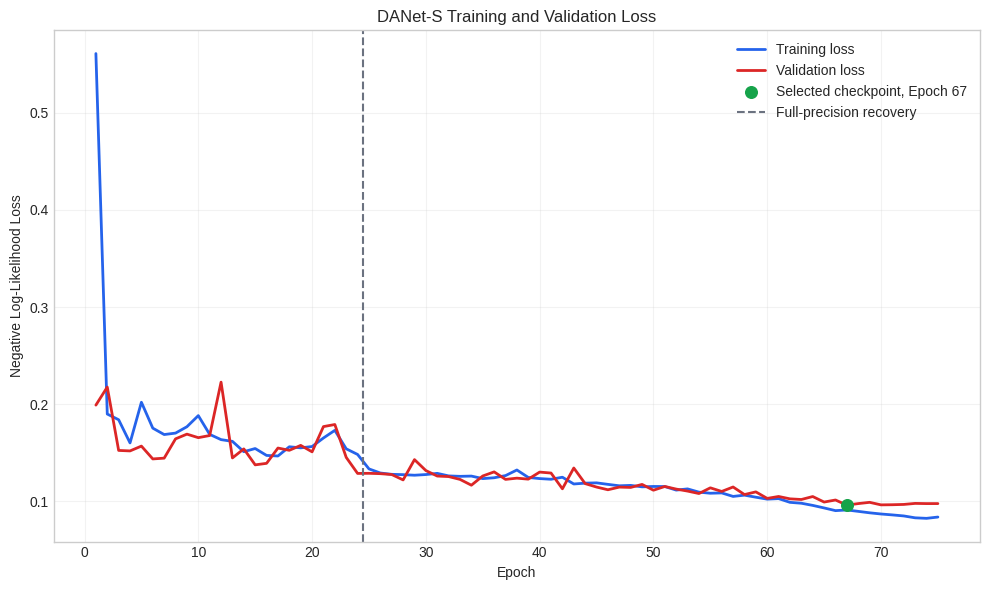

Loss figure saved to: /content/drive/MyDrive/malaria_danet/danet_training/figures/training_validation_loss.png


In [29]:
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

LOSS_FIGURE_PATH = FIGURES_DIR / "training_validation_loss.png"

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training loss",
    color="#2563EB",
    linewidth=2,
)

ax.plot(
    history_df["epoch"],
    history_df["validation_loss"],
    label="Validation loss",
    color="#DC2626",
    linewidth=2,
)

ax.scatter(
    best_epoch,
    best_saved_loss,
    color="#16A34A",
    s=70,
    zorder=3,
    label=f"Selected checkpoint, Epoch {best_epoch}",
)

ax.axvline(
    24.5,
    color="#6B7280",
    linestyle="--",
    linewidth=1.5,
    label="Full-precision recovery",
)

ax.set_title("DANet-S Training and Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Negative Log-Likelihood Loss")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    LOSS_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Loss figure saved to:", LOSS_FIGURE_PATH)

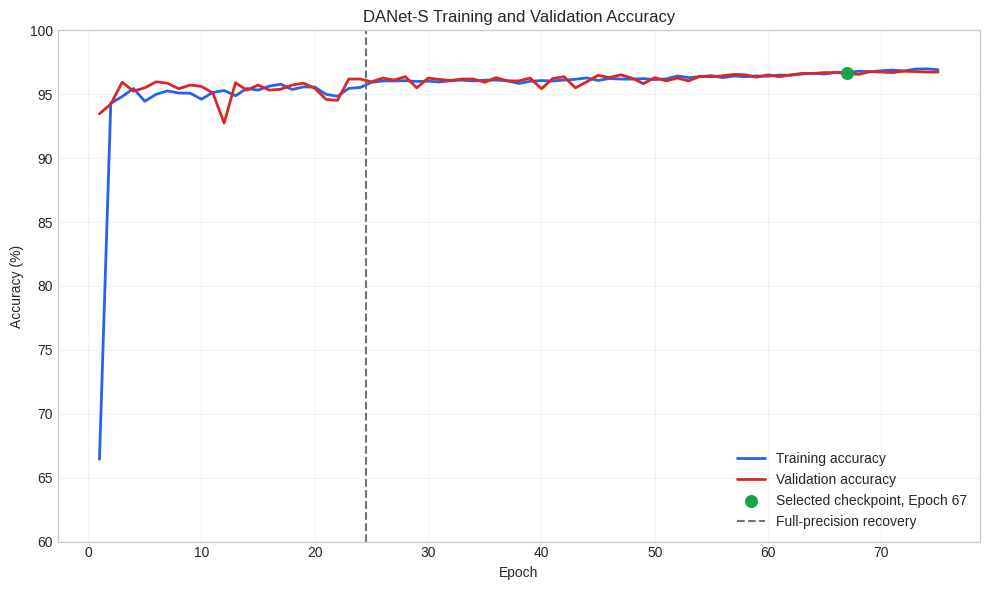

Accuracy figure saved to: /content/drive/MyDrive/malaria_danet/danet_training/figures/training_validation_accuracy.png


In [30]:
ACCURACY_FIGURE_PATH = (
    FIGURES_DIR / "training_validation_accuracy.png"
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    history_df["epoch"],
    history_df["train_accuracy"] * 100,
    label="Training accuracy",
    color="#2563EB",
    linewidth=2,
)

ax.plot(
    history_df["epoch"],
    history_df["validation_accuracy"] * 100,
    label="Validation accuracy",
    color="#DC2626",
    linewidth=2,
)

ax.scatter(
    best_epoch,
    best_saved_accuracy * 100,
    color="#16A34A",
    s=70,
    zorder=3,
    label=f"Selected checkpoint, Epoch {best_epoch}",
)

ax.axvline(
    24.5,
    color="#6B7280",
    linestyle="--",
    linewidth=1.5,
    label="Full-precision recovery",
)

ax.set_title("DANet-S Training and Validation Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(60, 100)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    ACCURACY_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Accuracy figure saved to:", ACCURACY_FIGURE_PATH)

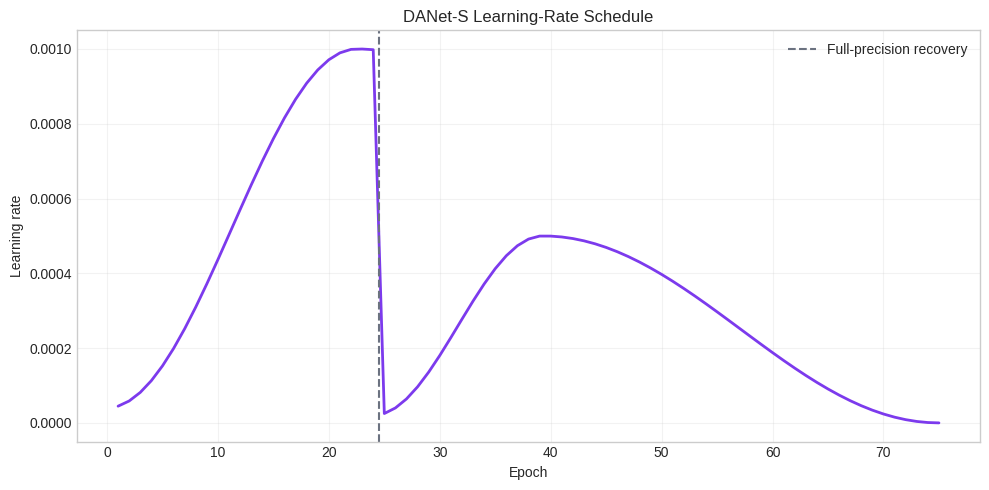

Learning-rate figure saved to: /content/drive/MyDrive/malaria_danet/danet_training/figures/learning_rate_schedule.png


In [31]:
LEARNING_RATE_FIGURE_PATH = (
    FIGURES_DIR / "learning_rate_schedule.png"
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    history_df["epoch"],
    history_df["learning_rate"],
    color="#7C3AED",
    linewidth=2,
)

ax.axvline(
    24.5,
    color="#6B7280",
    linestyle="--",
    linewidth=1.5,
    label="Full-precision recovery",
)

ax.set_title("DANet-S Learning-Rate Schedule")
ax.set_xlabel("Epoch")
ax.set_ylabel("Learning rate")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    LEARNING_RATE_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    "Learning-rate figure saved to:",
    LEARNING_RATE_FIGURE_PATH,
)

## 10. Training Summary

### Model and data

- Model: DANet-S
- Classes: Parasitized and Uninfected
- Input size: 224 x 224
- Training images: 19,290
- Validation images: 2,756
- Test images reserved for later evaluation: 5,512
- Trainable parameters: 2,310,842
- Random seed: 42

### Training configuration

- Optimizer: RMSprop
- Loss: Negative log-likelihood loss
- Scheduler: OneCycleLR
- Batch size: 64
- Completed epochs: 75
- Checkpoint criterion: Lowest validation loss
- Approximate retained training time: 155.0 minutes

### Training recovery

Training initially used mixed precision. Numerical instability occurred during the initial continuation, so the safe Epoch 24 checkpoint was restored. Training resumed from Epoch 25 in full precision with RMSprop reinitialized and a maximum learning rate of 0.0005. The final history contains the retained Epochs 1 through 24 followed by the stable full-precision Epochs 25 through 75.

### Selected checkpoint

- Selected epoch: 67
- Validation loss: 0.095962
- Validation accuracy: 0.966255
- Model file: danet_s_best_final.pth
- Model size: 8.90 MB
- SHA-256: `d08ff52e3c0682fadf0b23b631b916305405e1c9693e2f581dec26b5ba4f0aa1`

### Additional validation result

- Highest validation accuracy: 0.968070
- Highest-accuracy epoch: 72

### Final epoch

- Training loss: 0.083671
- Training accuracy: 0.969155
- Validation loss: 0.097548
- Validation accuracy: 0.967344

### Implementation note

The official public DANet-S implementation hardcodes more than two classifier outputs even though the malaria dataset is binary. This implementation uses two LogSoftMax outputs matching the saved class mapping.

### Evaluation boundary

The test split was not used during model development, training, checkpoint selection, or this validation summary. Final test evaluation is reserved for the evaluation stage.

The manifest uses an image-level split. Images from the same mapped patient may occur across training, validation, and test sets, which must be stated when interpreting the final results.


## 11. Saved Artifacts


In [32]:
with open(ARTIFACT_MANIFEST_PATH, "r") as file:
    artifact_records = json.load(file)

artifact_table = pd.DataFrame(artifact_records)
display(artifact_table)
print("Total finalized artifacts:", len(artifact_records))


file,size_mb,sha256
danet_s_best_final.pth,8.897,d08ff52e3c0682fadf0b23b631b916305405e1c9693e2f581dec26b5ba4f0aa1
danet_training_config_final.json,0.001,046ca02617edef9da18e273299e43777f4493158aa53e56bfc6ea58bccfd4c35
danet_training_history_final.csv,0.009,4be2a44d8298eb0b0a67b8e313800c72533ff924ed152324baac14701bae4d12
danet_training_summary.md,0.002,a1b5b8182661c87a903e4c878c4c2037b414bab256baa34888d705f5668a7f3c
figures/training_validation_loss.png,0.123,441f1345504c3c54ecef75ef4d906d3ff882a19501ef3f06736f1ef0f4912cc4
figures/training_validation_accuracy.png,0.112,8a66982858995d847f1d50f146c8629a3c669b47caa55c964cc002d4060282ec
figures/learning_rate_schedule.png,0.092,3fe961e3918154168445e57fee1fab53955e05e962710e32269014c044ebb477
danet_model.py,0.005,6823a446eb4b4f104837ddb1598074e5cb7de1dcd00e017e7e3a679511495cc2


Total finalized artifacts: 8


## 12. Limitations and Handoff

- The manifest uses an image-level split, so mapped patients overlap across training, validation, and test sets. Final results must be interpreted with this limitation.
- The model was developed on one public dataset and does not establish performance across laboratories, microscopes, staining procedures, or populations.
- The test split remains untouched in this notebook.
- The final checkpoint is stored externally and identified by its filename, size, and SHA-256 hash.
- Final test metrics, confusion matrix, ROC-AUC, and error analysis belong to the evaluation stage.
